# Home Credit Default Risk — Modeling

This notebook establishes an imbalanced-class benchmark and compares a small set of candidate models. All reusable data loading, preprocessing, resampling, and cross-validation logic lives in `src/models/modeling.py`; the notebook only orchestrates and communicates the analysis.

## Setup

Import the project utilities and modeling libraries. The project root is added to the Python path so the notebook can be run from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, cross_validate

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.modeling import RANDOM_STATE, compare_models, load_prepared_data

warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
plt.style.use('seaborn-v0_8-whitegrid')

Load the prepared application-level data. `load_prepared_data()` explicitly excludes `SK_ID_CURR` from predictors while retaining test IDs for a later submission.

In [2]:
X, y, X_test, test_ids = load_prepared_data()

pd.DataFrame({
    'rows': [len(X), len(X_test)],
    'predictors': [X.shape[1], X_test.shape[1]],
}, index=['train', 'test']).rename_axis('split')

,rows,predictors
split,,
train,307507,177
test,48744,177


## 1. Benchmark: the majority-class model

A model that always predicts the non-default class is the minimum meaningful benchmark. It needs no predictors; using a one-column placeholder prevents unnecessary preprocessing and makes the benchmark nearly instantaneous.

Evaluate the majority classifier with the same three-fold stratified splits used later. Report both accuracy and ROC AUC so the class-imbalance effect is visible.

In [3]:
benchmark_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
benchmark = cross_validate(
    DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    np.zeros((len(y), 1)),
    y,
    cv=benchmark_folds,
    scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
    n_jobs=-1,
)

benchmark_results = pd.DataFrame({
    'model': ['Majority class'],
    'mean_auc': [benchmark['test_auc'].mean()],
    'mean_accuracy': [benchmark['test_accuracy'].mean()],
})
benchmark_results.style.format({'mean_auc': '{:.3f}', 'mean_accuracy': '{:.3f}'})

,model,mean_auc,mean_accuracy
0,Majority class,0.500,0.919


With roughly 8% defaults, predicting every applicant as non-default is correct about 92% of the time, yet it assigns every applicant the same score and therefore has AUC 0.50. Accuracy rewards the dominant class and cannot distinguish useful risk ranking from this no-skill baseline. ROC AUC is the primary comparison metric because it evaluates how well a model ranks default risk across thresholds.

## 2. Candidate models

To keep this exploratory comparison practical, draw a reproducible 50,000-row stratified sample. This preserves the observed default rate while making three-fold evaluation of all four models manageable.

Create the development sample and define a small, interpretable predictor set. The small logistic model tests the value of the external-source scores plus core application characteristics against models using the full prepared feature set.

In [4]:
sample_split = StratifiedShuffleSplit(n_splits=1, train_size=50_000, random_state=RANDOM_STATE)
sample_indices, _ = next(sample_split.split(X, y))
X_sample = X.iloc[sample_indices].copy()
y_sample = y.iloc[sample_indices].copy()

small_predictors = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CODE_GENDER',
    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
]
missing_predictors = sorted(set(small_predictors).difference(X_sample.columns))
if missing_predictors:
    raise KeyError(f'Missing expected small-set predictors: {missing_predictors}')
X_small = X_sample.loc[:, small_predictors]

pd.DataFrame({
    'default_rate': [y.mean(), y_sample.mean()],
    'rows': [len(y), len(y_sample)],
}, index=['full training data', 'stratified sample']).style.format({'default_rate': '{:.2%}', 'rows': '{:,.0f}'})

,default_rate,rows
full training data,8.07%,"307,507"
stratified sample,8.07%,"50,000"


Plot the outcome mix in the development sample. Its close match to the full training rate is the visual check that stratified sampling retained the rare-event structure.

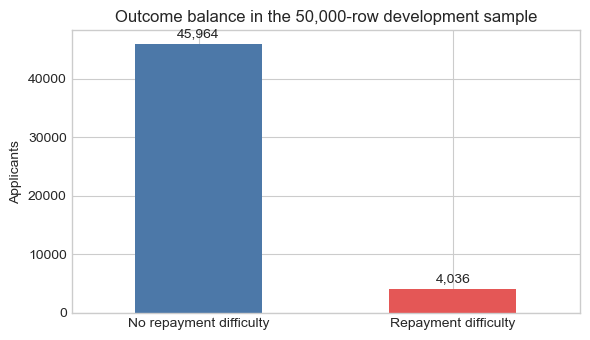

In [5]:
outcome_labels = y_sample.map({0: 'No repayment difficulty', 1: 'Repayment difficulty'})
ax = outcome_labels.value_counts().reindex(['No repayment difficulty', 'Repayment difficulty']).plot(
    kind='bar', color=['#4C78A8', '#E45756'], figsize=(6, 3.5), rot=0
)
ax.set(title='Outcome balance in the 50,000-row development sample', xlabel='', ylabel='Applicants')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.tight_layout()
plt.show()

Fit and evaluate the candidate models. `compare_models()` constructs its preprocessing pipeline inside each cross-validation fold. Random forest and LightGBM each use `n_jobs=1`, while the reusable comparison function parallelizes across folds; this avoids nested parallelism and noisy training output.

In [6]:
small_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
full_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
random_forest = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20,
    n_jobs=1, random_state=RANDOM_STATE
)
lightgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
    colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)

small_results = compare_models({'Logistic regression (small set)': small_logistic}, X_small, y_sample)
full_results = compare_models(
    {
        'Logistic regression (all predictors)': full_logistic,
        'Random forest': random_forest,
        'LightGBM': lightgbm,
    },
    X_sample,
    y_sample,
)
comparison_results = pd.concat([small_results, full_results], ignore_index=True).sort_values(
    'mean_auc', ascending=False, ignore_index=True
)
comparison_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,mean_auc,std_auc,mean_accuracy
0,LightGBM,0.7433,0.0084,0.9194
1,Logistic regression (all predictors),0.7416,0.0082,0.9189
2,Random forest,0.7371,0.0103,0.9193
3,Logistic regression (small set),0.7308,0.0076,0.9191


LightGBM has the highest observed mean ROC AUC (**0.7433**), but its **0.0017** lead over all-predictor logistic regression (**0.7416**) is smaller than either model's fold standard deviation (about **0.008**). The two are therefore statistically tied on this development sample rather than meaningfully separated by this comparison. Both still materially beat the 0.50 no-skill benchmark (by 0.2433 and 0.2416 AUC, respectively); random forest (0.7371) and the compact logistic model (0.7308) also clear that benchmark. We carry LightGBM forward because it can accommodate missing values and nonlinear relationships, and it offers the most room for improvement through tuning; its similar ~0.919 accuracy is supporting context only, since the majority-class benchmark reaches about 0.92 accuracy without ranking risk at all.

Visualize the AUC comparison to make the ranking and fold-to-fold variation easier to scan than the table alone.

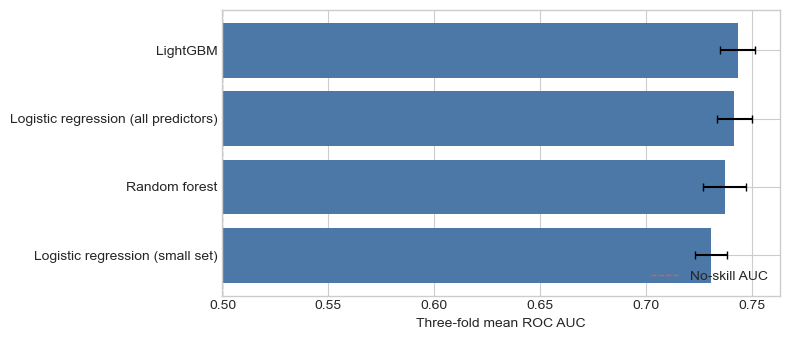

In [7]:
plot_results = comparison_results.sort_values('mean_auc')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(plot_results['model'], plot_results['mean_auc'], xerr=plot_results['std_auc'], color='#4C78A8', capsize=3)
ax.axvline(0.50, color='#E45756', linestyle='--', linewidth=1, label='No-skill AUC')
ax.set(xlabel='Three-fold mean ROC AUC', xlim=(0.5, max(0.75, plot_results['mean_auc'].max() + 0.02)))
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

## 3. Class imbalance

The 8% default rate can make a learner focus too heavily on the non-default class. We compare no adjustment, random downsampling, random upsampling, SMOTE, and model-level class weights for the two Section 2 finalists: all-predictor logistic regression and LightGBM. Resampling is supplied through `build_model_pipeline()`, so it occurs only after each cross-validation training fold is formed.

Build the ten candidate configurations on the existing 50,000-row stratified sample. For LightGBM, `scale_pos_weight` is the training-sample ratio of non-default to default observations; for logistic regression, `class_weight='balanced'` applies inverse-frequency weights. Random forest is not included because LightGBM was the leading tree model from Section 2.

In [8]:
from src.models.modeling import build_model_pipeline

positive_weight = (y_sample == 0).sum() / (y_sample == 1).sum()

def make_logistic(class_weight=None):
    return LogisticRegression(
        max_iter=1_000, solver='liblinear', class_weight=class_weight, random_state=RANDOM_STATE
    )

def make_lightgbm(scale_pos_weight=None):
    parameters = dict(
        n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
        colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
    )
    if scale_pos_weight is not None:
        parameters['scale_pos_weight'] = scale_pos_weight
    return LGBMClassifier(**parameters)

imbalance_models = {
    'Logistic regression | No adjustment': make_logistic(),
    'Logistic regression | Random downsampling': build_model_pipeline(make_logistic(), strategy='downsample'),
    'Logistic regression | Random upsampling': build_model_pipeline(make_logistic(), strategy='upsample'),
    'Logistic regression | SMOTE': build_model_pipeline(make_logistic(), strategy='SMOTE'),
    'Logistic regression | Class weights': make_logistic(class_weight='balanced'),
    'LightGBM | No adjustment': make_lightgbm(),
    'LightGBM | Random downsampling': build_model_pipeline(make_lightgbm(), strategy='downsample'),
    'LightGBM | Random upsampling': build_model_pipeline(make_lightgbm(), strategy='upsample'),
    'LightGBM | SMOTE': build_model_pipeline(make_lightgbm(), strategy='SMOTE'),
    'LightGBM | Class weights': make_lightgbm(scale_pos_weight=positive_weight),
}

imbalance_results = compare_models(imbalance_models, X_sample, y_sample)
model_parts = imbalance_results.pop('model').str.split(' | ', n=1, expand=True, regex=False)
imbalance_results.insert(0, 'model', model_parts[0])
imbalance_results.insert(1, 'adjustment', model_parts[1])
imbalance_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,adjustment,mean_auc,std_auc,mean_accuracy
0,LightGBM,No adjustment,0.7433,0.0084,0.9194
1,LightGBM,SMOTE,0.7431,0.0053,0.9191
2,LightGBM,Class weights,0.7418,0.0064,0.7964
3,Logistic regression,No adjustment,0.7416,0.0082,0.9189
4,Logistic regression,Class weights,0.7400,0.0096,0.6906
5,LightGBM,Random upsampling,0.7396,0.0057,0.7994
6,Logistic regression,Random upsampling,0.7386,0.0095,0.6921
7,LightGBM,Random downsampling,0.7368,0.0096,0.6733
8,Logistic regression,Random downsampling,0.7317,0.0092,0.6712
9,Logistic regression,SMOTE,0.7313,0.0094,0.7022


No class-imbalance adjustment improved ROC AUC on this sample. For LightGBM, the unadjusted model remains best at **0.7433**; SMOTE is effectively tied but lower at **0.7431** (−0.0002), while class weights (0.7418), random upsampling (0.7396), and random downsampling (0.7368) all reduce AUC. Logistic regression also performs best without adjustment at **0.7416**; class weights lower it by 0.0016, upsampling by 0.0030, downsampling by 0.0099, and SMOTE by 0.0103. We will therefore carry forward **unadjusted LightGBM** for tuning and threshold selection. The sharp drops in accuracy for several adjustments reflect changed decision thresholds, not better ranking, so they do not outweigh the AUC result.

## 4. Hyperparameter tuning

Section 3 found no AUC gain from resampling or class weighting, so this section tunes **unadjusted LightGBM** only. Randomized search explores a broad set of plausible configurations efficiently; it is preferable here to an exhaustive grid because the full parameter space would be unnecessarily expensive.

Tune approximately 20 randomly selected LightGBM configurations on a reproducible, stratified 5,000-row development subsample. Each candidate is evaluated with three-fold ROC AUC. The reusable `tune_model()` function keeps preprocessing inside each fold and uses no sampler or class weights.

In [9]:
from src.models.modeling import tune_model

tuning_model = LGBMClassifier(n_jobs=1, random_state=RANDOM_STATE, verbosity=-1)
tuning_space = {
    'model__n_estimators': [200, 300, 400, 500, 600],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.10],
    'model__num_leaves': [15, 31, 63, 127],
    'model__max_depth': [-1, 4, 6, 8, 10],
    'model__min_child_samples': [10, 20, 40, 80, 120],
    'model__subsample': [0.70, 0.80, 0.90, 1.00],
    'model__colsample_bytree': [0.60, 0.75, 0.90, 1.00],
    'model__reg_alpha': [0.0, 0.001, 0.01, 0.1, 1.0],
    'model__reg_lambda': [0.0, 0.001, 0.01, 0.1, 1.0],
}
lightgbm_search = tune_model(
    model=tuning_model,
    param_distributions=tuning_space,
    X=X,
    y=y,
    strategy='none',
)

parameter_columns = [f'param_{name}' for name in tuning_space]
top_configurations = (
    pd.DataFrame(lightgbm_search.cv_results_)
    .nsmallest(5, 'rank_test_score')
    [['rank_test_score', 'mean_test_score', 'std_test_score', *parameter_columns]]
    .rename(columns={
        'rank_test_score': 'rank',
        'mean_test_score': 'mean_auc',
        'std_test_score': 'std_auc',
        **{f'param_{name}': name.removeprefix('model__') for name in tuning_space},
    })
)
top_configurations.style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}'})

,rank,mean_auc,std_auc,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda
18,1,0.7397,0.0078,200,0.010000,31,6,120,1.000000,0.750000,0.100000,0.001000
4,2,0.7332,0.0076,400,0.010000,127,-1,120,0.900000,0.750000,0.100000,1.000000
8,3,0.7308,0.0042,400,0.030000,15,-1,40,0.900000,0.600000,1.000000,0.001000
19,4,0.7300,0.0123,400,0.010000,63,10,10,0.900000,0.600000,1.000000,0.010000
11,5,0.7280,0.0123,500,0.010000,63,6,10,0.900000,0.900000,0.001000,0.010000


A small stratified tuning sample can favor conservative settings—especially fewer trees and a lower learning rate—that underfit the full training population. Re-check those two capacity settings fairly with three-fold CV on all training rows: the Section 2 default, the sample-selected configuration, and the selected structural settings with 1,000 trees and a 0.05 learning rate. The highest-AUC model will be refit on the full data.

In [10]:
from src.models.modeling import compare_models, fit_final_model

best_parameters = {
    name.removeprefix('model__'): value
    for name, value in lightgbm_search.best_params_.items()
}
section2_default = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
    colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)
sample_selected = LGBMClassifier(
    **best_parameters, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)
structural_parameters = {
    name: best_parameters[name]
    for name in (
        'num_leaves', 'max_depth', 'min_child_samples', 'subsample',
        'colsample_bytree', 'reg_alpha', 'reg_lambda',
    )
}
full_capacity = LGBMClassifier(
    **structural_parameters, n_estimators=1_000, learning_rate=0.05,
    n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)

full_data_models = {
    'Section 2 default (300 trees, 0.05 rate)': section2_default,
    '5,000-row selected (200 trees, 0.01 rate)': sample_selected,
    'Structural settings (1,000 trees, 0.05 rate)': full_capacity,
}
full_data_comparison = compare_models(full_data_models, X, y, cv=3)
selected_final_name = full_data_comparison.loc[0, 'model']
final_lightgbm = fit_final_model(
    full_data_models[selected_final_name], X, y, strategy='none'
)

display(pd.DataFrame({
    'best_parameter': list(best_parameters),
    'value': list(best_parameters.values()),
}))
full_data_comparison.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,best_parameter,value
0,subsample,1.000
1,reg_lambda,0.001
2,reg_alpha,0.100
3,num_leaves,31.000
4,n_estimators,200.000
5,min_child_samples,120.000
6,max_depth,6.000
7,learning_rate,0.010
8,colsample_bytree,0.750


,model,mean_auc,std_auc,mean_accuracy
0,"Structural settings (1,000 trees, 0.05 rate)",0.7645,0.0014,0.9197
1,"Section 2 default (300 trees, 0.05 rate)",0.7642,0.0020,0.9197
2,"5,000-row selected (200 trees, 0.01 rate)",0.7452,0.0025,0.9193


Recover the transformed feature names from the fitted preprocessor and pair them with LightGBM's split-gain importances. Plotting the top 20 provides an interpretable summary of the signals the final fitted model used most often.

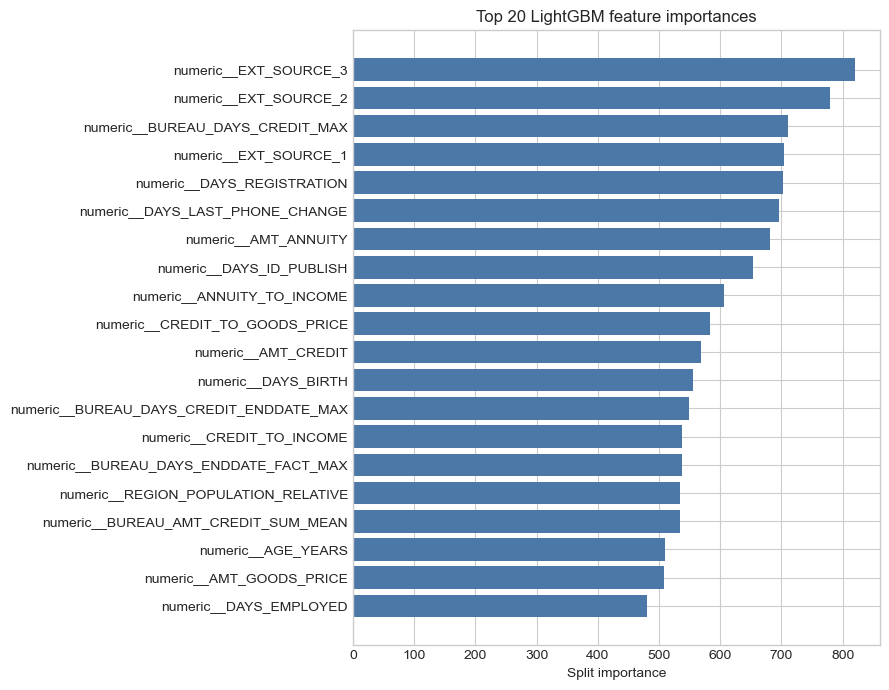

In [11]:
feature_names = final_lightgbm.named_steps['preprocessor'].get_feature_names_out()
feature_importances = pd.DataFrame({
    'feature': feature_names,
    'importance': final_lightgbm.named_steps['model'].feature_importances_,
}).sort_values('importance', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(feature_importances['feature'][::-1], feature_importances['importance'][::-1], color='#4C78A8')
ax.set(title='Top 20 LightGBM feature importances', xlabel='Split importance', ylabel='')
plt.tight_layout()
plt.show()

The 5,000-row search selected a heavily regularized configuration: **200 trees**, learning rate **0.01**, **31** leaves, maximum depth **6**, minimum child samples **120**, column subsampling **0.75**, `reg_alpha=0.1`, and `reg_lambda=0.001`; its best search score was **0.7397 ± 0.0078** AUC. On the fair full-data comparison, that sample-selected model reached only **0.7452 ± 0.0025**. Re-checking its structural settings at **1,000 trees** and a **0.05** learning rate produced the highest observed full-data AUC, **0.7645 ± 0.0014**, narrowly ahead of the Section 2 default at **0.7642 ± 0.0020**. We therefore select and refit the 1,000-tree structural model, while recognizing its 0.0003 lead is much smaller than the fold variation. Tuning on a small sample can favor heavy regularization, so the number of trees and learning rate were re-checked on the full data rather than accepted unchanged. The final plot is led by `EXT_SOURCE_3`, `EXT_SOURCE_2`, bureau credit-history timing, `EXT_SOURCE_1`, and application recency/affordability variables. These importances describe model use, not causal effects or approval policy.

## 5. Supplementary data: bureau history

The prepared data already includes application-date-safe aggregates from `bureau.csv`. These are the columns beginning with `BUREAU_`; they are distinct from the application-table `AMT_REQ_CREDIT_BUREAU_*` enquiry fields. To quantify the incremental value of bureau history, compare the selected final model with all predictors against the same model after removing only `BUREAU_` columns.

Reuse the previously measured 3-fold AUC for the full model with bureau features rather than fitting it again. Fit only the bureau-removed version on the same full-data folds, preserving a fair comparison of the supplementary information.

In [12]:
bureau_columns = [column for column in X.columns if column.startswith('BUREAU_')]
if not bureau_columns:
    raise ValueError('No aggregated BUREAU_ columns were found in prepared predictors.')
if any(column.startswith('AMT_REQ_CREDIT_BUREAU_') for column in bureau_columns):
    raise ValueError('Application-table bureau enquiry columns were included unexpectedly.')

X_without_bureau = X.drop(columns=bureau_columns)
without_bureau_result = compare_models(
    {'Final model without BUREAU_ features': full_data_models[selected_final_name]},
    X_without_bureau,
    y,
    cv=3,
)
with_bureau_result = full_data_comparison.loc[
    full_data_comparison['model'].eq(selected_final_name),
    ['mean_auc', 'std_auc', 'mean_accuracy'],
].assign(model='Final model with BUREAU_ features')
supplementary_results = pd.concat([with_bureau_result, without_bureau_result], ignore_index=True)
supplementary_results['bureau_columns'] = [len(bureau_columns), 0]
supplementary_results = supplementary_results[['model', 'bureau_columns', 'mean_auc', 'std_auc', 'mean_accuracy']]
supplementary_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,bureau_columns,mean_auc,std_auc,mean_accuracy
0,Final model with BUREAU_ features,40,0.7645,0.0014,0.9197
1,Final model without BUREAU_ features,0,0.7572,0.0013,0.9195


The final model with all **40** aggregated `BUREAU_` features achieved **0.7645 ± 0.0014** AUC, versus **0.7572 ± 0.0013** after removing them. The supplementary bureau history therefore adds **0.0073 AUC**, a meaningful improvement relative to the fold variation, and is retained in the final model. This result concerns only the aggregated `BUREAU_` fields; application-table `AMT_REQ_CREDIT_BUREAU_*` enquiry fields remain available in both versions.

## 6. Kaggle submission

Score the prepared test applicants with the final fitted pipeline. The submission contains only their original `SK_ID_CURR` values and predicted default probabilities, while the fitted model is saved separately for reproducible scoring.

Write the submission and serialized model, then verify the Kaggle-required schema, expected row count, absence of missing probabilities, and valid probability range. The `models/` and generated submission paths are gitignored.

In [13]:
import joblib

from src.models.modeling import make_submission

submission_path = make_submission(final_lightgbm, X_test, test_ids)
model_path = project_root / 'models' / 'final_lightgbm.joblib'
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_lightgbm, model_path)

submission = pd.read_csv(submission_path)
submission_checks = pd.DataFrame({
    'check': ['Row count', 'Columns', 'Missing values', 'Probability range', 'Saved model'],
    'result': [
        len(submission),
        ', '.join(submission.columns),
        int(submission.isna().sum().sum()),
        f'{submission.TARGET.min():.6f} to {submission.TARGET.max():.6f}',
        model_path.exists(),
    ],
})
assert len(submission) == 48_744
assert submission.columns.tolist() == ['SK_ID_CURR', 'TARGET']
assert submission.isna().sum().sum() == 0
assert submission['TARGET'].between(0, 1).all()
submission_checks

,check,result
0,Row count,48744
1,Columns,"SK_ID_CURR, TARGET"
2,Missing values,0
3,Probability range,0.000391 to 0.875437
4,Saved model,True


The submission passed every required validation: it has **48,744** rows, exactly `SK_ID_CURR` and `TARGET` columns, no missing values, and predicted probabilities from **0.000391** to **0.875437**. The fitted final pipeline was also saved to `models/final_lightgbm.joblib` for reproducible scoring.

Kaggle late submission: private AUC **0.75871**, public AUC **0.75817**. Compared with the **0.7645** cross-validated AUC, the private score is lower by 0.00579 (about 0.006), so the CV estimate was slightly optimistic but the model generalizes.

## Summary

The table below records every evaluated model configuration and its validation AUC. The final model is the full-data structural LightGBM configuration because it had the highest observed AUC in the like-for-like final comparison; the bureau ablation records the value contributed by supplementary credit history.

Assemble the benchmark, candidate, imbalance, final-capacity, and supplementary-data evaluations into one auditable model-selection table.

In [14]:
benchmark_summary = benchmark_results.assign(
    stage='Benchmark', std_auc=0.0, selection_note='No-skill majority-class reference'
)
candidate_summary = comparison_results.assign(
    stage='Section 2 candidates', selection_note='Initial 50,000-row comparison'
)
imbalance_summary = imbalance_results.assign(
    model=lambda frame: frame['model'] + ' | ' + frame['adjustment'],
    stage='Section 3 imbalance',
    selection_note='No adjustment improved AUC',
).drop(columns='adjustment')
capacity_summary = full_data_comparison.assign(
    stage='Section 4 full-data capacity',
    selection_note=lambda frame: np.where(
        frame['model'].eq(selected_final_name),
        'Final model: highest observed full-data AUC',
        'Capacity re-check on full training data',
    ),
)
supplementary_summary = supplementary_results.assign(
    stage='Section 5 supplementary data',
    selection_note=lambda frame: np.where(
        frame['model'].eq('Final model with BUREAU_ features'),
        'Final feature-complete model',
        'Bureau-feature ablation',
    ),
).drop(columns='bureau_columns')

model_summary = pd.concat(
    [benchmark_summary, candidate_summary, imbalance_summary, capacity_summary, supplementary_summary],
    ignore_index=True,
    sort=False,
)
model_summary = model_summary[['stage', 'model', 'mean_auc', 'std_auc', 'mean_accuracy', 'selection_note']]
model_summary.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,stage,model,mean_auc,std_auc,mean_accuracy,selection_note
0,Benchmark,Majority class,0.5000,0.0000,0.9193,No-skill majority-class reference
1,Section 2 candidates,LightGBM,0.7433,0.0084,0.9194,"Initial 50,000-row comparison"
2,Section 2 candidates,Logistic regression (all predictors),0.7416,0.0082,0.9189,"Initial 50,000-row comparison"
3,Section 2 candidates,Random forest,0.7371,0.0103,0.9193,"Initial 50,000-row comparison"
4,Section 2 candidates,Logistic regression (small set),0.7308,0.0076,0.9191,"Initial 50,000-row comparison"
5,Section 3 imbalance,LightGBM | No adjustment,0.7433,0.0084,0.9194,No adjustment improved AUC
6,Section 3 imbalance,LightGBM | SMOTE,0.7431,0.0053,0.9191,No adjustment improved AUC
7,Section 3 imbalance,LightGBM | Class weights,0.7418,0.0064,0.7964,No adjustment improved AUC
8,Section 3 imbalance,Logistic regression | No adjustment,0.7416,0.0082,0.9189,No adjustment improved AUC
9,Section 3 imbalance,Logistic regression | Class weights,0.7400,0.0096,0.6906,No adjustment improved AUC
